# LiveRecall public test plots
Reads `tests/test_results/public/{v5,v6}/tN_run0X.json`, takes the median of 3 runs, and writes PNGs into `docs/figures/` for `REPORT.md`.

In [1]:
import json, statistics
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().resolve().parents[1]          # run from docs/figures
RES = ROOT / "tests" / "test_results" / "public"
OUT = Path.cwd()
TESTS = ["t1", "t2", "t3", "t4", "t5"]
PAL = {"v5": "#1F77B4", "v6": "#2CA02C"}          # matches \vfive / \vsix colours

def get(d, key):
    for k in key.split("."):
        d = d[k]
    return d

def median(ver, test, key):
    runs = sorted(RES.glob(f"{ver}/{test}_run*.json"))
    return statistics.median(get(json.loads(p.read_text()), key) for p in runs)

def tidy(keys):
    """Long-form frame: one row per (version, test, metric) median."""
    return pd.DataFrame([{"version": v, "test": t.upper(), "metric": lab, "value": median(v, t, k)}
                         for v in PAL for t in TESTS for lab, k in keys.items()])

def label_bars(ax, fmt="{:.1f}", **kw):
    for c in ax.containers:
        ax.bar_label(c, labels=[fmt.format(b.get_height()) for b in c], padding=1.5,
                     fontsize=7, **kw)

sns.set_theme(style="ticks", context="paper", font_scale=1.1)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. Caption age percentiles, v5 vs v6

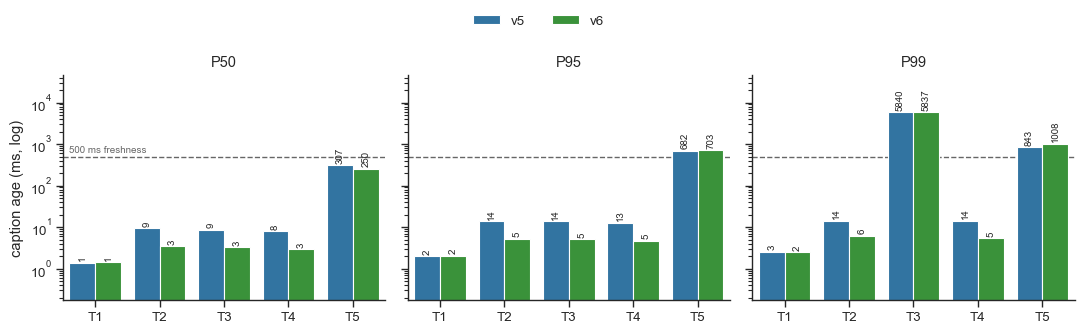

In [2]:
lat = tidy({"P50": "p50_ms", "P95": "p95_ms", "P99": "p99_ms"})
g = sns.catplot(lat, kind="bar", x="test", y="value", hue="version", col="metric",
                palette=PAL, height=3.2, aspect=1.15, sharey=True, legend_out=False)
g.set(yscale="log"); g.set_axis_labels("", "caption age (ms, log)"); g.set_titles("{col_name}")
for ax in g.axes.flat:
    label_bars(ax, "{:.0f}", rotation=90)
    ax.margins(y=0.25)
    ax.axhline(500, ls="--", lw=1, color="0.4", zorder=0)
g.axes.flat[0].text(-0.4, 560, "500 ms freshness", va="bottom", ha="left", fontsize=7, color="0.4")
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, title=None, frameon=False)
g.savefig(OUT / "latency_v5_v6.png", dpi=200, bbox_inches="tight")

## 2. Freshness / fresh-final / completeness / coverage, v5 vs v6

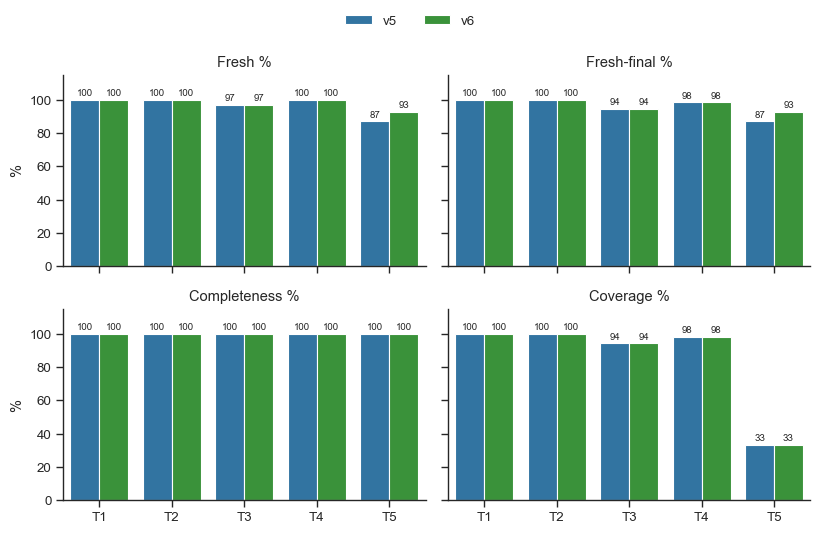

In [3]:
# Fresh vs fresh-final side by side (top row), completeness/coverage (bottom row), v5 vs v6
fc = tidy({"Fresh %": "fresh_pct", "Fresh-final %": "fresh_final_pct",
           "Completeness %": "final_completeness_pct", "Coverage %": "normal_update_coverage_pct"})
g = sns.catplot(fc, kind="bar", x="test", y="value", hue="version", col="metric", col_wrap=2,
                palette=PAL, height=2.6, aspect=1.6, legend_out=False)
g.set(ylim=(0, 115)); g.set_axis_labels("", "%"); g.set_titles("{col_name}")
for ax in g.axes.flat:
    label_bars(ax, "{:.0f}")
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, title=None, frameon=False)
g.savefig(OUT / "fresh_coverage_v6.png", dpi=200, bbox_inches="tight")

## 3. T3: normal vs slow clients (v6)

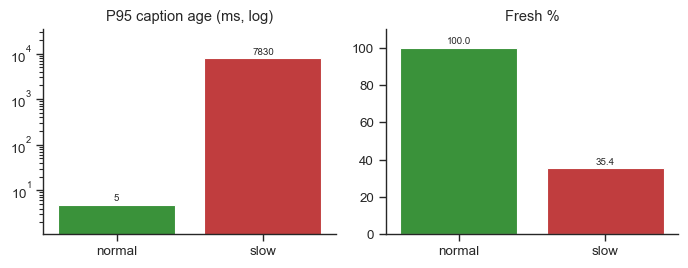

In [4]:
groups = {"normal": "normal_clients", "slow": "slow_clients"}
t3 = pd.DataFrame([{"client": lab, "P95 caption age (ms, log)": median("v6", "t3", f"{g}.p95_ms"),
                    "Fresh %": median("v6", "t3", f"{g}.fresh_pct")} for lab, g in groups.items()])
cols = {"normal": "#2CA02C", "slow": "#D62728"}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7, 2.8))
for a, m, fmt in [(a1, "P95 caption age (ms, log)", "{:.0f}"), (a2, "Fresh %", "{:.1f}")]:
    sns.barplot(t3, x="client", y=m, hue="client", palette=cols, ax=a, legend=False)
    a.set(title=m, xlabel="", ylabel=""); label_bars(a, fmt)
a1.set_yscale("log"); a1.margins(y=0.2); a2.set_ylim(0, 110)
fig.tight_layout(); fig.savefig(OUT / "t3_isolation.png", dpi=200)